# 08 – Fine-tune PhoBERT (chạy trên **Google Colab hoặc Kaggle**, có GPU)

Notebook này **không chạy trên máy bạn**. Các bước:

1. Colab: *Runtime → Change runtime type → T4 GPU*.
2. Tải lên Colab (biểu tượng thư mục bên trái) 5 file trong `data/processed/`: `visd_train.csv`, `visd_dev.csv`, `visd_test.csv`, `shopee_train_relabel.csv`, `shopee_gold_pool.csv`. Kaggle thì tạo Dataset rồi sửa `DATA` bên dưới.
3. *Run all*. Mỗi cấu hình mất khoảng 10–15 phút trên T4.
4. Tải `phobert_outputs.zip` về, giải nén vào `report/phobert/` trong dự án. Notebook 09 sẽ tự đọc.

**Thiết kế:**
- Train trên **A+B** (giống mô hình cổ điển).
- Chọn checkpoint bằng **ViSD4SA dev**, không dùng tập vàng.
- Thử 2 learning rate; đó là phần "tinh chỉnh siêu tham số" của PhoBERT.
- Không làm 5-fold CV vì mỗi lần fine-tune tốn 10–15 phút GPU. **Ghi lý do này vào báo cáo.**
- Lưu xác suất dự đoán trên **toàn bộ 746 câu kho vàng**. Notebook 09 tự lọc ra các câu bạn đã gán nhãn, nên **không cần chạy lại PhoBERT** khi gán thêm.
**Lưu ý tái lập bản nhãn gán lại (10/11):** mã đọc `shopee_train_relabel.csv` (nhãn gán lại nằm ở cột `weak_label`, pos/neg/neu = 1153/591/44) và ghi tên tệp cùng số dòng vào `config.json`. Lần chạy Colab cho kết quả trong `report/phobert/` diễn ra trước khi có dòng ghi nguồn này, nên vẫn chưa xác minh được tệp đầu vào của lần chạy đó; notebook không được chạy lại.


In [6]:
!pip -q install transformers accelerate

In [7]:
import os, json, zipfile
import numpy as np, pandas as pd, torch
from torch import nn
from datasets import Dataset
from sklearn.metrics import f1_score, classification_report
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

DATA = "/content"                 # Kaggle: "/kaggle/input/<ten-dataset>"
OUT = "/content/phobert_outputs"  # Kaggle: "/kaggle/working/phobert_outputs"
os.makedirs(OUT, exist_ok=True)
set_seed(42)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ GPU, hãy bật GPU")

LABELS = ["neg", "neu", "pos"]
L2I = {l: i for i, l in enumerate(LABELS)}

def load(f, label_col):
    d = pd.read_csv(f"{DATA}/{f}")
    return d.rename(columns={label_col: "label"})

A = load("visd_train.csv", "label"); A_dev = load("visd_dev.csv", "label"); A_test = load("visd_test.csv", "label")
TRAIN_B = "shopee_train_relabel.csv"   # nhãn gán lại 08/11 (cột weak_label)
B = load(TRAIN_B, "weak_label")
pool = load("shopee_gold_pool.csv", "weak_label")
train = pd.concat([A[["text_prep", "label"]], B[["text_prep", "label"]]], ignore_index=True)
print(len(train), train.label.value_counts().to_dict())

GPU: Tesla T4
9138 {'pos': 5761, 'neg': 2877, 'neu': 500}


PhoBERT cần văn bản **đã tách từ** ("hài_lòng"). Cột `text_prep` đã được tách bằng underthesea.

In [8]:
MODEL = "vinai/phobert-base"
tok = AutoTokenizer.from_pretrained(MODEL)

def to_ds(df, with_label=True):
    d = Dataset.from_pandas(df[["text_prep"] + (["label"] if with_label else [])].reset_index(drop=True))
    d = d.map(lambda b: tok(b["text_prep"], truncation=True, max_length=128), batched=True)
    if with_label:
        d = d.map(lambda b: {"labels": [L2I[x] for x in b["label"]]}, batched=True)
    return d.remove_columns([c for c in ["text_prep", "label"] if c in d.column_names])

ds_train, ds_dev = to_ds(train), to_ds(A_dev)
ds_test, ds_pool = to_ds(A_test), to_ds(pool, with_label=False)

lens = [len(x) for x in tok(train.text_prep.tolist())["input_ids"]]
print("Tỉ lệ câu dài hơn 128 token:", np.mean(np.array(lens) > 128).round(3))

Map:   0%|          | 0/9138 [00:00<?, ? examples/s]

Map:   0%|          | 0/9138 [00:00<?, ? examples/s]

Map:   0%|          | 0/1046 [00:00<?, ? examples/s]

Map:   0%|          | 0/1046 [00:00<?, ? examples/s]

Map:   0%|          | 0/2120 [00:00<?, ? examples/s]

Map:   0%|          | 0/2120 [00:00<?, ? examples/s]

Map:   0%|          | 0/746 [00:00<?, ? examples/s]

Tỉ lệ câu dài hơn 128 token: 0.009


**Trọng số lớp:** lớp neu chỉ chiếm khoảng 5%. Dùng hàm mất mát có trọng số (giống `class_weight="balanced"` của sklearn) để mô hình không bỏ qua lớp này.

In [9]:
counts = train.label.value_counts().reindex(LABELS).values
class_w = torch.tensor(len(train) / (len(LABELS) * counts), dtype=torch.float)
print("Trọng số lớp:", dict(zip(LABELS, class_w.numpy().round(2))))

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels")
        out = model(**inputs)
        loss = nn.CrossEntropyLoss(weight=class_w.to(out.logits.device))(out.logits, labels)
        return (loss, out) if return_outputs else loss

def compute_metrics(p):
    return {"f1_macro": f1_score(p.label_ids, p.predictions.argmax(-1), average="macro")}

Trọng số lớp: {'neg': np.float32(1.06), 'neu': np.float32(6.09), 'pos': np.float32(0.53)}


In [10]:
results, best = [], None
for lr in [2e-5, 3e-5]:
    model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=3)
    args = TrainingArguments(f"out_lr{lr}", learning_rate=lr, num_train_epochs=4,
                             per_device_train_batch_size=32, per_device_eval_batch_size=64,
                             eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
                             load_best_model_at_end=True, metric_for_best_model="f1_macro",
                             save_total_limit=1, warmup_steps=int(0.1 * 4 * len(ds_train) / 32), weight_decay=0.01,
                             seed=42, fp16=True, report_to="none")
    tr = WeightedTrainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_dev,
                         data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
    tr.train()
    f1_dev = tr.evaluate()["eval_f1_macro"]
    json.dump(tr.state.log_history, open(f"{OUT}/log_history_lr{lr}.json", "w"))
    results.append({"lr": lr, "f1_dev": f1_dev})
    print(f"lr={lr}: F1 dev = {f1_dev:.3f}")
    if best is None or f1_dev > best[0]:
        best = (f1_dev, lr, tr)
pd.DataFrame(results).to_csv(f"{OUT}/lr_search.csv", index=False)
print("Chọn lr =", best[1])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1 Macro
1,0.757347,0.428277,0.798068
2,0.473374,0.445732,0.692293
3,0.345810,0.405931,0.796727
4,0.264250,0.475871,0.802314


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,F1 Macro
0.212213,0.543166,4,0.816985


lr=3e-05: F1 dev = 0.817
Chọn lr = 3e-05


In [11]:
tr = best[2]
def proba(ds):
    logits = tr.predict(ds).predictions
    return torch.softmax(torch.tensor(logits), -1).numpy()

p_test = proba(ds_test)
print("ViSD4SA test F1-macro:", round(f1_score(A_test.label, [LABELS[i] for i in p_test.argmax(1)], average="macro"), 3))
print(classification_report(A_test.label, [LABELS[i] for i in p_test.argmax(1)], digits=3))
pd.DataFrame(p_test, columns=[f"p_{l}" for l in LABELS]).assign(label=A_test.label.values).to_csv(
    f"{OUT}/phobert_visd_test_proba.csv", index=False)

p_pool = proba(ds_pool)
pd.DataFrame(p_pool, columns=[f"p_{l}" for l in LABELS]).assign(id=pool.id.values).to_csv(
    f"{OUT}/phobert_gold_pool_proba.csv", index=False)
json.dump({"model": MODEL, "train": "A+B", "train_file_B": TRAIN_B, "n_train_B": len(B), "best_lr": best[1], "epochs": 4, "max_length": 128,
           "batch": 32, "class_weight": True}, open(f"{OUT}/config.json", "w"))

ViSD4SA test F1-macro: 0.808
              precision    recall  f1-score   support

         neg      0.943     0.914     0.928       685
         neu      0.478     0.620     0.540        71
         pos      0.957     0.957     0.957      1364

    accuracy                          0.932      2120
   macro avg      0.793     0.830     0.808      2120
weighted avg      0.936     0.932     0.934      2120



## Đường loss train / validation (learning curve của PhoBERT)

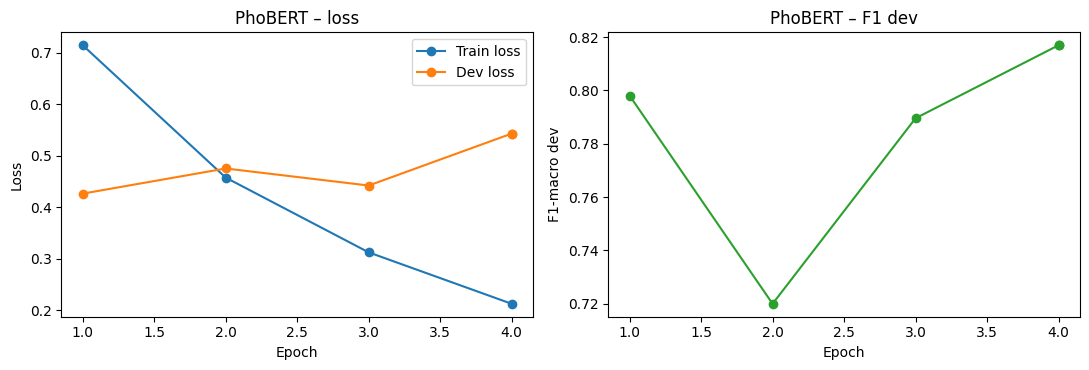

In [12]:
import matplotlib.pyplot as plt
h = pd.DataFrame(json.load(open(f"{OUT}/log_history_lr{best[1]}.json")))
tl = h.dropna(subset=["loss"])[["epoch", "loss"]]
ev = h.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_f1_macro"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tl.epoch, tl.loss, "o-", label="Train loss"); ax[0].plot(ev.epoch, ev.eval_loss, "o-", label="Dev loss")
ax[0].set(xlabel="Epoch", ylabel="Loss", title="PhoBERT – loss"); ax[0].legend()
ax[1].plot(ev.epoch, ev.eval_f1_macro, "o-", color="C2"); ax[1].set(xlabel="Epoch", ylabel="F1-macro dev", title="PhoBERT – F1 dev")
plt.tight_layout(); plt.savefig(f"{OUT}/phobert_loss.png", dpi=150, bbox_inches="tight"); plt.show()

In [13]:
with zipfile.ZipFile("/content/phobert_outputs.zip", "w") as z:   # Kaggle: đổi đường dẫn
    for f in os.listdir(OUT):
        z.write(f"{OUT}/{f}", f)
print("Tải file phobert_outputs.zip về, giải nén vào report/phobert/")

Tải file phobert_outputs.zip về, giải nén vào report/phobert/
